# Exploratory data analysis
Key patterns in the HR Analytics dataset that motivated the feature engineering in `src/jobchange/features.py`.

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from jobchange import config as C
sns.set_theme(style='whitegrid')
df = pd.read_csv(C.TRAIN_CSV)
print(df.shape); df['target'].value_counts(normalize=True).rename('share')

(19158, 14)


target
0.0    0.750652
1.0    0.249348
Name: share, dtype: float64

## 1. Class imbalance
25% of candidates are looking for a job change, so accuracy alone is misleading: we use PR-AUC, recall/precision and lift.

## 2. Missingness is informative
Missing company info is *not* random: those candidates move far more often (this became the `is_unemployed` feature).

In [2]:
rows = []
for col in ['company_size','company_type','gender','major_discipline','education_level']:
    rows.append({'column': col, 'missing': df[col].isna().mean(),
                 'target rate if missing': df.loc[df[col].isna(),'target'].mean(),
                 'target rate if present': df.loc[df[col].notna(),'target'].mean()})
pd.DataFrame(rows).round(3)

,column,missing,target rate if missing,target rate if present
0,company_size,0.310,0.406,0.179
1,company_type,0.320,0.388,0.184
2,gender,0.235,0.308,0.231
3,major_discipline,0.147,0.195,0.259
4,education_level,0.024,0.226,0.250


## 3. City development index

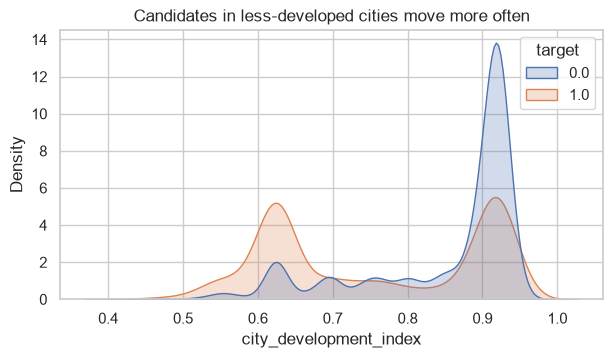

In [3]:
fig, ax = plt.subplots(figsize=(7,3.5))
sns.kdeplot(data=df, x='city_development_index', hue='target', common_norm=False, fill=True, ax=ax)
ax.set_title('Candidates in less-developed cities move more often'); plt.show()

## 4. Experience and tenure

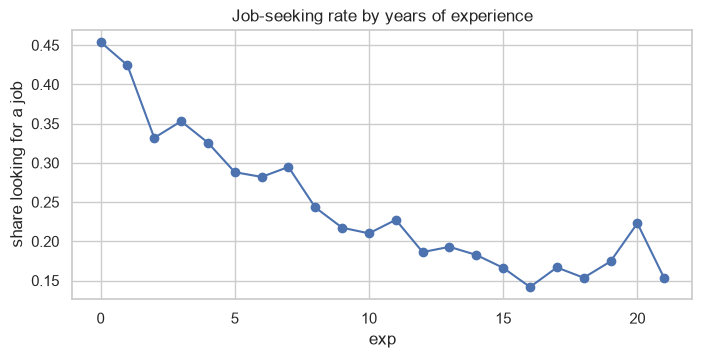

In [4]:
exp = df['experience'].replace({'<1':'0','>20':'21'}); exp = pd.to_numeric(exp, errors='coerce')
fig, ax = plt.subplots(figsize=(8,3.5))
df.assign(exp=exp).groupby('exp')['target'].mean().plot(marker='o', ax=ax)
ax.set(ylabel='share looking for a job', title='Job-seeking rate by years of experience'); plt.show()

## 5. Company size and enrollment

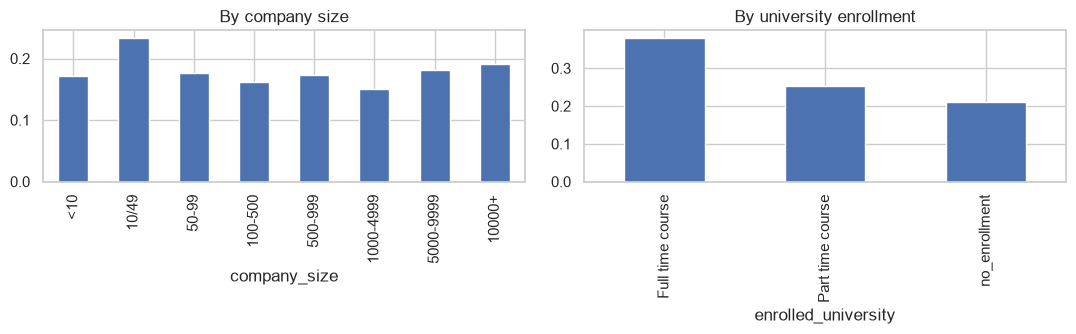

In [5]:
order = ['<10','10/49','50-99','100-500','500-999','1000-4999','5000-9999','10000+']
fig, axes = plt.subplots(1,2, figsize=(11,3.5))
df.groupby('company_size')['target'].mean().reindex(order).plot.bar(ax=axes[0], title='By company size')
df.groupby('enrolled_university')['target'].mean().plot.bar(ax=axes[1], title='By university enrollment')
plt.tight_layout(); plt.show()

## 6. Training hours
Weak signal on its own; kept (log-scaled) for the model.

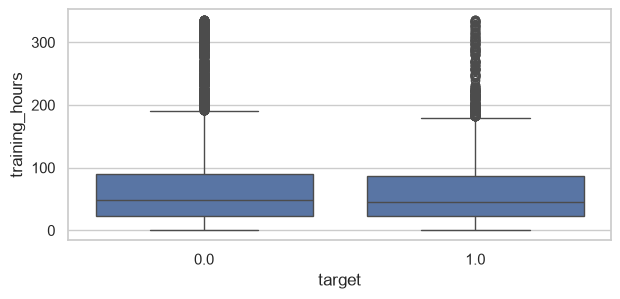

In [6]:
fig, ax = plt.subplots(figsize=(7,3)); sns.boxplot(data=df, x='target', y='training_hours', ax=ax); plt.show()